# Módulo 5 — Transformações Box–Cox

## Seção 2 — Família Box–Cox: definição, limite logarítmico, propriedades e inversão

**Estado editorial:** primeira versão para revisão matemática e pedagógica. **Pré-requisitos:** Seção 1 do Módulo 5, funções potência, logaritmos, limites, derivação e familiaridade básica com NumPy. **Programação integrada:** Python 3, NumPy, Matplotlib e SciPy. **Convenção:** $x>0$ representa valor observado na escala original; $\lambda\in\mathbb R$ é o parâmetro da transformação; $w$ representa o valor transformado.

**Fontes e alcance.** O plano prioritário exige fórmula, limite em $\lambda=0$, domínio, inversão e discussão de hipóteses. O mapeamento das videoaulas registra cobertura apenas **parcial** das deduções de Box–Cox, com uso aplicado na Aula 2 — Parte II (STL/MSTL) e em parte do curso ARIMA. As deduções analíticas e exemplos desta seção são **complementações didáticas originais**. A estimação de $\lambda$ por perfil de verossimilhança, transformação de previsões e correção de viés serão aprofundadas em seções seguintes; não atribuímos essas fórmulas a páginas não verificadas de Morettin e Toloi.

### Objetivos

Compreender a construção da família Box–Cox; demonstrar a continuidade no caso $\lambda=0$; deduzir derivada e inversa; identificar as restrições de domínio; discutir mudanças de concavidade e escala; implementar e validar transformações usando Python sem confundir valores transformados com valores originais.

### 1. Definição formal

Para um número estritamente positivo $x$, a família Box–Cox é

$$
\boxed{
g_\lambda(x)=
\begin{cases}
\dfrac{x^\lambda-1}{\lambda}, & \lambda\ne0,\\[6pt]
\log x, & \lambda=0.
\end{cases}
}
$$

As potências são bem definidas para todo $\lambda$ real quando $x>0$, pois $x^\lambda=\exp(\lambda\log x)$. O parâmetro $\lambda$ **não** é um índice temporal e não deve ser confundido com a defasagem $h$ da ACF nem com o índice de frequência utilizado futuramente em análise espectral.

O termo $-1$ e o divisor $\lambda$ são importantes: garantem uma passagem contínua ao logaritmo quando $\lambda\to0$ e fazem com que $g_\lambda(1)=0$ para qualquer $\lambda$.

### 2. Por que o logaritmo aparece quando $\lambda\to0$?

Fixe $x>0$ e denote $a=\log x$. Para $\lambda\ne0$,

$$
g_\lambda(x)=\frac{\exp(\lambda a)-1}{\lambda}.
$$

Pela expansão de Taylor em torno de zero,

$$
\exp(\lambda a)=1+\lambda a+\frac{\lambda^2a^2}{2}+O(\lambda^3).
$$

Substituindo,

$$
\begin{aligned}
g_\lambda(x)
&=\frac{\lambda a+\lambda^2a^2/2+O(\lambda^3)}{\lambda}\\
&=a+\frac{\lambda a^2}{2}+O(\lambda^2).
\end{aligned}
$$

Consequentemente,

$$
\boxed{\lim_{\lambda\to0}g_\lambda(x)=\log x.}
$$

A demonstração pressupõe $x>0$ **fixo**. É também possível utilizar a regra de l'Hôpital, derivando o numerador e denominador em relação a $\lambda$; a derivada do numerador é $x^\lambda\log x$.

**Exemplo numérico:** para $x=4$, os valores $g_1(4)=3$, $g_{1/2}(4)=2$, $g_0(4)=\log4\approx1{,}38629$ e $g_{-1}(4)=0{,}75$. A transformação não é uma simples multiplicação por constante: ela modifica a geometria de distâncias entre níveis.

### 3. Derivada, monotonicidade e concavidade

Para $\lambda\ne0$,

$$
\frac{d}{dx}g_\lambda(x)=\frac{\lambda x^{\lambda-1}}{\lambda}=x^{\lambda-1}.
$$

No caso $\lambda=0$, temos $d(\log x)/dx=1/x=x^{-1}$, portanto a identidade vale em todos os casos:

$$
\boxed{g'_\lambda(x)=x^{\lambda-1}>0,\qquad x>0.}
$$

Isso prova que **todas** as transformações da família são estritamente crescentes: preservam a ordem das observações. Mas não preservam necessariamente diferenças, razões, médias ou correlações.

A derivada de segunda ordem é

$$
g''_\lambda(x)=(\lambda-1)x^{\lambda-2}.
$$

Logo, a transformação é côncava para $\lambda<1$, linear para $\lambda=1$ e convexa para $\lambda>1$; $\lambda=0$ é o caso logarítmico, côncavo. A concavidade é uma propriedade **matemática**, não a prova de que uma série transformada possui variância constante.

Da aproximação delta desenvolvida na Seção 1,

$$
\mathrm{Var}[g_\lambda(X)]\approx\mu^{2(\lambda-1)}\mathrm{Var}(X),\qquad \mu=E[X]>0.
$$

Se $\mathrm{DP}(X)\approx C\mu^p$, a escolha heurística $\lambda\approx1-p$ neutraliza a dependência da dispersão em relação ao nível, dentro das hipóteses do método delta. Em amostras reais, a escolha de $\lambda$ pode depender de outras características do modelo.

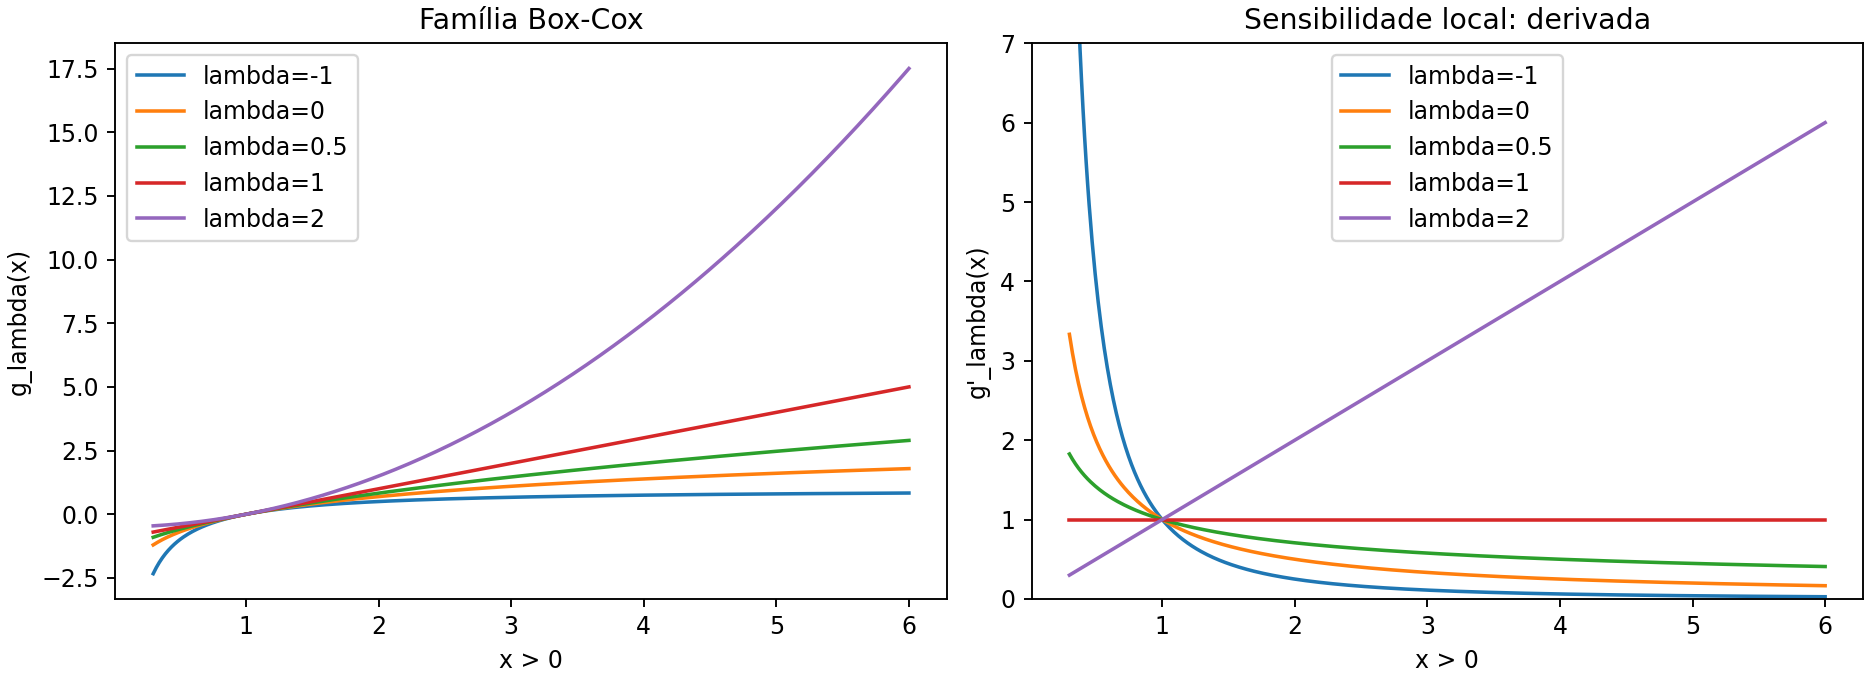

*Figura 1 — Transformações $g_\lambda(x)$ e derivadas $g'_\lambda(x)$ para cinco valores de $\lambda$. As curvas preservam a ordem dos dados, mas alteram a sensibilidade a diferenças em níveis baixos e altos. O eixo da derivada foi limitado por legibilidade.*

### 4. Casos especiais e suas interpretações

| Parâmetro | Fórmula | Interpretação |
|---|---|---|
| $\lambda=1$ | $x-1$ | Apenas desloca a escala; não estabiliza variância por si só |
| $\lambda=0$ | $\log x$ | Converte efeitos multiplicativos em aditivos no logaritmo |
| $\lambda=1/2$ | $2(\sqrt x-1)$ | Variação proporcional à raiz quadrada, com constante e escala |
| $\lambda=-1$ | $1-x^{-1}$ | Compressão intensa de valores grandes |
| $\lambda=2$ | $(x^2-1)/2$ | Aumenta a sensibilidade a valores grandes |

**Exemplo resolvido:** sejam $x_1=1$, $x_2=4$, $x_3=9$. Com $\lambda=1/2$:

$$
(g_{1/2}(1),g_{1/2}(4),g_{1/2}(9))=(0,2,4).
$$

Com $\lambda=0$:

$$
(g_0(1),g_0(4),g_0(9))=(0,\log4,\log9).
$$

A ordem $1<4<9$ foi preservada, mas as distâncias mudaram. Não interprete uma variação de uma unidade transformada como uma variação de uma unidade na escala original.

### 5. Inversa e domínio da inversa

Para $\lambda\ne0$, suponha que $w=g_\lambda(x)$. Então:

$$
\begin{aligned}
w&=\frac{x^\lambda-1}{\lambda},\\
\lambda w&=x^\lambda-1,\\
1+\lambda w&=x^\lambda.
\end{aligned}
$$

Assim,

$$
\boxed{g_\lambda^{-1}(w)=(1+\lambda w)^{1/\lambda},\quad 1+\lambda w>0.}
$$

Para $\lambda=0$, como $w=\log x$, segue $x=\exp(w)$, isto é,

$$
\boxed{g_0^{-1}(w)=\exp(w).}
$$

A condição $1+\lambda w>0$ não é decorativa: garante que o resultado da potência real seja positivo para $\lambda$ geral. Para $\lambda>0$, a imagem de $g_\lambda$ é $(-1/\lambda,\infty)$; para $\lambda<0$, é $(-\infty,-1/\lambda)$. No caso logarítmico, a imagem é toda a reta real.

**Atenção estatística:** em geral,

$$
g_\lambda^{-1}\bigl(E[g_\lambda(X)]\bigr)\ne E[X].
$$

Por exemplo, se $\log X\sim N(\mu,\sigma^2)$, então a inversa de $E[\log X]=\mu$ é $\exp(\mu)$, a mediana de $X$; sua média é $\exp(\mu+\sigma^2/2)$. A reversão de previsões exige cuidado com o **alvo estatístico** (média, mediana ou outro funcional). Isso será aprofundado mais adiante.

### 6. Dados nulos, negativos, deslocamentos e precipitação

A transformação **padrão** Box–Cox requer $x>0$. Em séries de precipitação, zeros podem representar ausência real de chuva, enquanto valores ausentes representam falhas de medição; os dois não são intercambiáveis. Não devemos substituir valores ausentes por zero apenas para aplicar a transformação.

Um deslocamento $x+c$ com $c>0$ pode tornar os dados positivos, mas **altera o modelo e a interpretação**. O parâmetro $\lambda$ estimado pode mudar com a escolha de $c$, assim como a transformação inversa passa a exigir subtrair $c$. Para dados com zeros verdadeiros ou números negativos, outras famílias (por exemplo, Yeo–Johnson) ou modelos com componente de ocorrência e intensidade podem ser mais apropriados. Não adotaremos nenhuma dessas alternativas sem justificar a aplicação.

Transformações também interagem com a unidade de medida: mudar a unidade de $x$ pode alterar valores transformados e deslocamentos interpretativos, mesmo que ajustes de modelos com intercepto possam absorver algumas mudanças.

### 7. Implementação manual em Python e comparação com SciPy

**Dependências:** NumPy para funções exponencial/logarítmica e vetorização; SciPy para conferência da implementação; Matplotlib para a figura da família. `np.expm1(z)` calcula $e^z-1$ com maior precisão para $z$ pequeno, o que melhora a estabilidade numérica quando $\lambda$ está perto de zero.

In [ ]:
import numpy as np
from scipy.stats import boxcox

def boxcox_manual(x, lam):
    x = np.asarray(x, dtype=float)
    if np.any(x <= 0):
        raise ValueError('Os dados devem ser estritamente positivos.')
    if np.isclose(lam, 0.0):
        return np.log(x)
    return np.expm1(lam * np.log(x)) / lam

def inversa_boxcox(w, lam):
    w = np.asarray(w, dtype=float)
    if np.isclose(lam, 0.0):
        return np.exp(w)
    base = 1 + lam*w
    if np.any(base <= 0):
        raise ValueError('Exige-se 1 + lambda*w > 0.')
    return base ** (1/lam)

amostra = np.array([1., 2., 4., 8.])
for lam in (-1, 0, 0.5, 1, 2):
    w = boxcox_manual(amostra, lam)
    assert np.allclose(w, boxcox(amostra, lmbda=lam))
    assert np.allclose(inversa_boxcox(w, lam), amostra)
    print(lam, np.round(w, 4))


`np.isclose` identifica, para o exercício, valores numéricos muito próximos de zero e usa o ramo logarítmico. Isso é uma **decisão de implementação**, e não parte exata da definição matemática: para aplicações que exijam fidelidade à transformação com $\lambda$ minúsculo, prefira o cálculo `np.expm1(lam*np.log(x))/lam` para todo $\lambda\ne0`, com tratamento explícito apenas de zero.

O procedimento `boxcox(amostra, lmbda=lam)` recebe $\lambda$ fixo e devolve os valores transformados. **Não** estamos estimando $\lambda$ nesta seção; passar `lmbda=None` introduziria um problema de estimação que ainda será estudado. `np.allclose` verifica concordância numérica dentro de uma tolerância, não uma demonstração matemática da correção geral do programa.

A aplicação em séries temporais deve respeitar a separação cronológica: ao avaliar previsão, parâmetros de transformação escolhidos a partir de dados devem ser ajustados somente no conjunto de treinamento. Isso será formalizado ao estudar a estimação de $\lambda$.

### 8. Exercícios graduais

1. **Limite:** demonstre o caso $\lambda=0$ pela regra de l'Hôpital, declarando o que permanece fixo.
2. **Derivada:** calcule $g'_\lambda(x)$ e $g''_\lambda(x)$, interpretando sinais para $\lambda=0$, $1/2$ e $2$.
3. **Cálculo:** para $x=9$, compute $g_0(x)$, $g_{1/2}(x)$ e $g_1(x)$.
4. **Inversa:** encontre o domínio de $g_2^{-1}$ e aplique a inversa ao valor transformado de $x=3$.
5. **Python:** altere o exemplo para testar $\lambda=0{,}0001$. Compare `np.expm1` com a expressão direta `(x**lam-1)/lam` e explique possíveis diferenças de precisão.
6. **Interpretativo:** uma série meteorológica contém zeros reais e registros ausentes. Explique por que não se deve aplicar `np.log(x)` indiscriminadamente.
7. **Aprofundamento:** usando a aproximação delta, justifique por que $\lambda\approx1-p$ é uma candidata quando o desvio padrão cresce aproximadamente como $\mu^p$. Declare o caráter aproximado do argumento.

**Respostas selecionadas:** no exercício 3, $g_0(9)=\log9$, $g_{1/2}(9)=4$ e $g_1(9)=8$. No exercício 4, $g_2^{-1}(w)=\sqrt{1+2w}$ exige $w>-1/2$; para $x=3$, $w=4$ e a inversa vale $3$.

### Síntese

A família Box–Cox reúne transformações de potência em uma parametrização contínua, incluindo o logaritmo. Monotonicidade preserva ordenação; a derivada explica a compressão ou expansão local da escala; a inversa restitui valores positivos somente no domínio matemático correto. **Nenhuma dessas propriedades, isoladamente, garante variância estável ou boa previsão.** A seleção estatística de $\lambda$ depende de uma modelagem e será estudada em uma etapa específica.

### Referências e rastreabilidade

- `PLANO_MODULOS_PRIORITARIOS.md`, Módulo 5: requisitos e ressalvas metodológicas (consultado).
- `mapeamento-conteudos-series-temporais.md`, Aula 2 — Parte II e quadro de Box–Cox (consultado; cobertura parcial das deduções).
- Morettin, P. A.; Toloi, C. M. C. *Análise de Séries Temporais: modelos lineares univariados*, vol. 1, 3. ed. Referência principal do projeto, **sem atribuição de seção/página não verificada neste capítulo**.
- Definição, limite, derivadas, exemplo da inversa, código e exercícios: **desenvolvimento didático complementar**. A família de transformações é conhecida na literatura como Box–Cox; a demonstração aqui é uma elaboração própria.